# DSCI 552 Homework 7

Name: Zhisong Han  
GitHub Username: zshan666  
USC ID: 5284161601

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import calinski_harabasz_score
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Multi-class and Multi-Label Classification Using Support Vector Machines

## 1(a) Load and Split the Anuran Calls Data

In [2]:
data_path = "data/Frogs_MFCCs.csv"
df = pd.read_csv(data_path)
print("Shape:", df.shape)

Shape: (7195, 26)


In [3]:
feature_cols = [col for col in df.columns if col.startswith("MFCCs")]
label_cols = ["Family", "Genus", "Species"]
X = df[feature_cols]
y = df[label_cols]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)
print("Number of features:", len(feature_cols))
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Number of features: 22
Training set: (5036, 22)
Test set: (2159, 22)
Training labels: (5036, 3)
Test labels: (2159, 3)


## 1(b) Multi-label Classification

### 1(b)(i) Evaluation Metrics

Exact match measures the proportion of observations for which all three labels are predicted correctly.

Hamming loss is the fraction of individual labels that are predicted incorrectly. A smaller value is better.

Hamming score is defined here as 1 minus the Hamming loss, so a larger value is better.

In [4]:
def evaluate_multilabel(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    exact_match = np.mean(
        np.all(y_true == y_pred, axis=1)
    )
    h_loss = np.mean(y_true != y_pred)
    h_score = 1 - h_loss
    return exact_match, h_score, h_loss

### 1(b)(ii) Gaussian Kernel SVM

In [5]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)
rbf_predictions = pd.DataFrame(
    index=y_test.index,
    columns=label_cols
)
rbf_results = []
for label in label_cols:
    model = OneVsRestClassifier(
        SVC(kernel="rbf")
    )
    param_grid = {
        "estimator__C": [0.1, 1, 10, 100],
        "estimator__gamma": [0.01, 0.1, 1]
    }
    grid = GridSearchCV(
        model,
        param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    grid.fit(X_train, y_train[label])
    rbf_predictions[label] = grid.predict(X_test)
    rbf_results.append({
        "Label": label,
        "Best C": grid.best_params_["estimator__C"],
        "Best gamma": grid.best_params_["estimator__gamma"],
        "CV Accuracy": grid.best_score_
    })
rbf_results_df = pd.DataFrame(rbf_results)
rbf_results_df

,Label,Best C,Best gamma,CV Accuracy
0,Family,100,1,0.991460
1,Genus,10,1,0.991064
2,Species,10,1,0.990074


In [6]:
rbf_exact, rbf_h_score, rbf_h_loss = evaluate_multilabel(
    y_test,
    rbf_predictions
)
print("Exact Match:", rbf_exact)
print("Hamming Score:", rbf_h_score)
print("Hamming Loss:", rbf_h_loss)

Exact Match: 0.9874942102825383
Hamming Score: 0.9922803767176162
Hamming Loss: 0.0077196232823838196


### 1(b)(iii) L1-Penalized SVM

In [7]:
l1_predictions = pd.DataFrame(
    index=y_test.index,
    columns=label_cols
)
l1_results = []
for label in label_cols:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=50000,
            random_state=42
        ))
    ])
    param_grid = {
        "svm__C": [0.01, 0.1, 1, 10, 100]
    }
    grid = GridSearchCV(
        model,
        param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    grid.fit(X_train, y_train[label])
    l1_predictions[label] = grid.predict(X_test)
    l1_results.append({
        "Label": label,
        "Best C": grid.best_params_["svm__C"],
        "CV Accuracy": grid.best_score_
    })
l1_results_df = pd.DataFrame(l1_results)
l1_results_df

,Label,Best C,CV Accuracy
0,Family,10,0.941223
1,Genus,100,0.951551
2,Species,10,0.960682


In [8]:
l1_exact, l1_h_score, l1_h_loss = evaluate_multilabel(
    y_test,
    l1_predictions
)
print("Exact Match:", l1_exact)
print("Hamming Score:", l1_h_score)
print("Hamming Loss:", l1_h_loss)

Exact Match: 0.9124594719777674
Hamming Score: 0.9430291801760075
Hamming Loss: 0.05697081982399259


### 1(b)(iv) L1-Penalized SVM with SMOTE

In [9]:
smote_predictions = pd.DataFrame(
    index=y_test.index,
    columns=label_cols
)
smote_results = []
for label in label_cols:
    model = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=50000,
            random_state=42
        ))
    ])
    param_grid = {
        "svm__C": [0.01, 0.1, 1, 10, 100]
    }
    grid = GridSearchCV(
        model,
        param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    grid.fit(X_train, y_train[label])
    smote_predictions[label] = grid.predict(X_test)
    smote_results.append({
        "Label": label,
        "Best C": grid.best_params_["svm__C"],
        "CV Accuracy": grid.best_score_
    })
smote_results_df = pd.DataFrame(smote_results)
smote_results_df

,Label,Best C,CV Accuracy
0,Family,10,0.923156
1,Genus,1,0.912837
2,Species,10,0.958103


In [10]:
smote_exact, smote_h_score, smote_h_loss = evaluate_multilabel(
    y_test,
    smote_predictions
)
print("Exact Match:", smote_exact)
print("Hamming Score:", smote_h_score)
print("Hamming Loss:", smote_h_loss)

Exact Match: 0.8536359425660027
Hamming Score: 0.9231125521074571
Hamming Loss: 0.07688744789254284


### Comparison

The RBF SVM performs best, with an exact match of about 0.9875 and the lowest Hamming loss of about 0.0077. The L1-SVM performs worse, with an exact match of about 0.9125. After applying SMOTE, the exact match decreases to about 0.8536. Therefore, SMOTE did not improve the overall performance for this data set.

# 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

In [11]:
X_all = df[feature_cols]
y_all = df[label_cols]
print("Features:", X_all.shape)
print("Labels:", y_all.shape)

Features: (7195, 22)
Labels: (7195, 3)


## 2(a) Selecting the Number of Clusters

I use the Calinski-Harabasz score to select the number of clusters. Since this score requires at least two clusters, I search over \(k=2,\ldots,50\).

In [12]:
k_values = range(2, 51)
ch_scores = []
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    cluster_labels = kmeans.fit_predict(X_all)
    score = calinski_harabasz_score(
        X_all,
        cluster_labels
    )
    ch_scores.append(score)
best_k = list(k_values)[np.argmax(ch_scores)]
print("Best k:", best_k)
print("Best CH score:", max(ch_scores))

Best k: 2
Best CH score: 3680.7413494630914


## 2(b) Majority Labels in Each Cluster

In [13]:
best_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)
best_clusters = best_kmeans.fit_predict(X_all)
cluster_df = y_all.copy()
cluster_df["Cluster"] = best_clusters
majority_labels = (
    cluster_df
    .groupby("Cluster")[label_cols]
    .agg(lambda x: x.mode().iloc[0])
)
majority_labels

,Family,Genus,Species
Cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


## 2(c) Hamming Distance, Score, and Loss

In [14]:
cluster_predictions = pd.DataFrame(
    index=y_all.index,
    columns=label_cols
)
for i in range(len(y_all)):
    cluster = best_clusters[i]
    cluster_predictions.iloc[i] = majority_labels.loc[cluster]
mismatches = (
    np.asarray(y_all) != np.asarray(cluster_predictions)
)
avg_hamming_distance = mismatches.sum(axis=1).mean()
hamming_loss_value = mismatches.mean()
hamming_score_value = 1 - hamming_loss_value
print("Average Hamming Distance:", avg_hamming_distance)
print("Hamming Score:", hamming_score_value)
print("Hamming Loss:", hamming_loss_value)

Average Hamming Distance: 0.8956219596942321
Hamming Score: 0.7014593467685892
Hamming Loss: 0.2985406532314107


## Monte Carlo Simulation

I repeat the clustering procedure 50 times using different random seeds. In each run, I select the best \(k\) using the Calinski-Harabasz score, assign majority labels to each cluster, and calculate the Hamming distance, score, and loss.

In [15]:
mc_results = []
for seed in range(50):
    scores = []
    for k in range(2, 51):
        km = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10
        )
        labels = km.fit_predict(X_all)
        scores.append(
            calinski_harabasz_score(X_all, labels)
        )
    best_k_mc = np.argmax(scores) + 2
    km = KMeans(
        n_clusters=best_k_mc,
        random_state=seed,
        n_init=10
    )
    clusters = km.fit_predict(X_all)
    temp = y_all.copy()
    temp["Cluster"] = clusters
    majority = (
        temp.groupby("Cluster")[label_cols]
        .agg(lambda x: x.mode().iloc[0])
    )
    predictions = np.array([
        majority.loc[c].values
        for c in clusters
    ])
    true_labels = y_all.to_numpy()
    mismatches = true_labels != predictions
    h_distance = mismatches.sum(axis=1).mean()
    h_loss = mismatches.mean()
    h_score = 1 - h_loss
    mc_results.append({
        "k": best_k_mc,
        "Hamming Distance": h_distance,
        "Hamming Score": h_score,
        "Hamming Loss": h_loss
    })
mc_results_df = pd.DataFrame(mc_results)
summary = mc_results_df[
    ["Hamming Distance", "Hamming Score", "Hamming Loss"]
].agg(["mean", "std"])
summary

,Hamming Distance,Hamming Score,Hamming Loss
mean,8.956220e-01,7.014593e-01,2.985407e-01
std,1.121495e-16,1.121495e-16,5.607473e-17


In [16]:
mc_results_df["k"].value_counts().sort_index()

k
2    50
Name: count, dtype: int64

# 3. ISLR 12.6.2

## 3(a) Complete Linkage

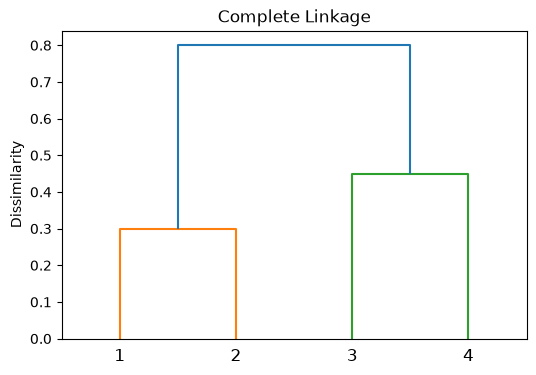

In [17]:
D = np.array([
    [0.0, 0.3, 0.4, 0.7],
    [0.3, 0.0, 0.5, 0.8],
    [0.4, 0.5, 0.0, 0.45],
    [0.7, 0.8, 0.45, 0.0]
])
condensed_D = squareform(D)
Z_complete = linkage(
    condensed_D,
    method="complete"
)
plt.figure(figsize=(6, 4))
dendrogram(
    Z_complete,
    labels=["1", "2", "3", "4"]
)
plt.ylabel("Dissimilarity")
plt.title("Complete Linkage")
plt.show()

## 3(b) Single Linkage

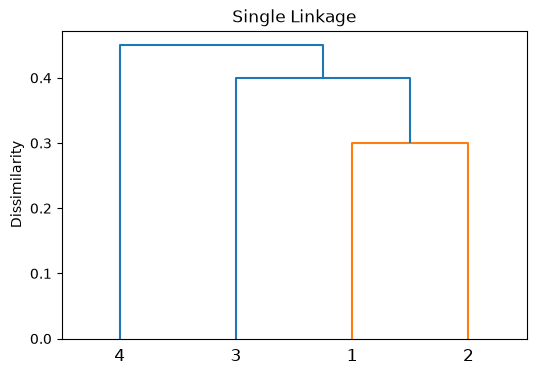

In [18]:
Z_single = linkage(
    condensed_D,
    method="single"
)
plt.figure(figsize=(6, 4))
dendrogram(
    Z_single,
    labels=["1", "2", "3", "4"]
)
plt.ylabel("Dissimilarity")
plt.title("Single Linkage")
plt.show()

## 3(c)

For complete linkage, cutting the dendrogram to obtain two clusters gives:

- Cluster 1: observations 1 and 2
- Cluster 2: observations 3 and 4

## 3(d)

For single linkage, cutting the dendrogram to obtain two clusters gives:

- Cluster 1: observations 1, 2, and 3
- Cluster 2: observation 4

## 3(e)

An equivalent dendrogram can be obtained by swapping the positions of the observations within the two branches. The clustering structure and fusion heights remain unchanged.

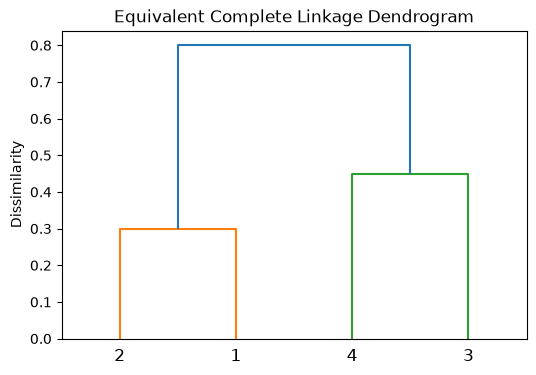

In [19]:
order = [1, 0, 3, 2]
D_reordered = D[np.ix_(order, order)]
Z_equivalent = linkage(
    squareform(D_reordered),
    method="complete"
)
plt.figure(figsize=(6, 4))
dendrogram(
    Z_equivalent,
    labels=["2", "1", "4", "3"]
)
plt.ylabel("Dissimilarity")
plt.title("Equivalent Complete Linkage Dendrogram")
plt.show()